# Notebook 7 — Topic Modelling and Hidden Complaint Themes

## Objective

This notebook applies unsupervised topic modelling to consumer complaint narratives to discover recurring themes that may not be fully represented by the existing CFPB issue and sub-issue labels.

The analysis aims to:

- Identify hidden themes within complaint narratives.
- Compare alternative topic-modelling configurations.
- Select a useful and interpretable topic structure.
- Measure actual topic volumes using the full narrative dataset.
- Compare topic distributions fairly across products.
- Examine relationships between discovered topics, companies and sentiment.
- Produce reusable topic assignments for the financial-intelligence KPI and SQL layers.

## Data Usage

Three prepared datasets serve different purposes:

1. **Unique topic-training corpus**  
   Used to train the topic model without allowing exact duplicate narratives to dominate the discovered themes.

2. **Full narrative dataset**  
   Used to calculate real topic volumes and operational complaint patterns.

3. **Equal-product corpus**  
   Used only for fair comparisons between products because each product contributes the same number of narratives.

Text cleaning from Notebook 5 will not be repeated.

## Methodology

The topic-modelling pipeline consists of:

1. Load and validate the prepared narrative datasets.
2. Select a balanced comparison sample for efficient model development.
3. Convert narratives into semantic sentence embeddings.
4. Handle narratives exceeding the embedding model's token limit through bounded text chunks and average chunk embeddings.
5. Reduce embedding dimensionality using UMAP.
6. identify dense narrative groups using HDBSCAN.
7. Generate interpretable topic keywords using BERTopic's class-based TF-IDF representation.
8. Compare several clustering configurations using:
   - Number and size of discovered topics
   - Percentage of narratives classified as outliers
   - Topic keyword distinctiveness
   - Topic-size balance
   - Qualitative inspection of keywords and representative narratives
9. Select the most useful configuration.
10. Apply the selected pipeline to the unique full training corpus in Google Colab.
11. Map topic assignments back to all complaint records.
12. Analyse topics across products, companies and FinBERT sentiment.

The same semantic embeddings will be reused when comparing clustering configurations, avoiding unnecessary repeated computation.

## Exploratory Interpretation

Topic modelling is unsupervised: no predefined correct topic exists for each narrative. Therefore, conventional supervised metrics such as accuracy, precision, recall and F1-score are not applicable.

Topic quality will be evaluated through statistical diagnostics, topic distinctiveness and qualitative interpretability. The final topics should be treated as exploratory analytical groupings rather than objectively verified complaint categories.

## Computational Strategy

Initial validation and setup will be completed locally. Heavy embedding generation and full-corpus topic modelling will be performed in Google Colab using a GPU.

Saved embeddings and topic assignments will be reused throughout the remaining project. Embeddings will not need to be regenerated for Notebook 8 or the SQL analytics layer.

## 2. File Setup and Schema Check

This section locates the prepared datasets and inspects their existing columns. No text cleaning or topic modelling is performed here.

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

DATA_DIR = Path(
    "/Users/ishika/Documents/AIProject/data/processed"
)

FULL_DATA_PATH = (
    DATA_DIR / "full_narratives_prepared.csv"
)

EQUAL_PRODUCT_PATH = (
    DATA_DIR / "equal_product_nlp_corpus.csv"
)

print("Full dataset exists:", FULL_DATA_PATH.exists())
print("Equal-product dataset exists:", EQUAL_PRODUCT_PATH.exists())

full_columns = pd.read_csv(
    FULL_DATA_PATH,
    nrows=0
).columns.tolist()

equal_columns = pd.read_csv(
    EQUAL_PRODUCT_PATH,
    nrows=0
).columns.tolist()

print("\nFull dataset columns:")
print(full_columns)

print("\nEqual-product dataset columns:")
print(equal_columns)

Full dataset exists: True
Equal-product dataset exists: True

Full dataset columns:
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'complaint_id', 'source_file', 'has_narrative', 'narrative_character_count', 'narrative_word_count', 'cleaned_narrative', 'has_cleaned_narrative', 'narrative_repeat_count', 'is_repeated_narrative', 'zip_code_status', 'zip3', 'sub_issue_available', 'issue_detail', 'issue_theme', 'narrative_text', 'narrative_char_count', 'is_short_narrative', 'is_long_narrative', 'narrative_topic_text', 'topic_word_count', 'topic_model_eligible', 'normalized_text_frequency']

Equal-product dataset columns:
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zip_code', 'tags', '

## 3. Loading the Prepared Topic Corpora

Only the columns required for topic modelling and later interpretation are loaded. The prepared `narrative_topic_text` column is used directly, so text cleaning from Notebook 5 is not repeated.

Exact duplicate topic texts are removed only from the model-training corpus to prevent repeated narratives from dominating topic discovery. All complaint records remain available for final volume analysis.

In [13]:
ID_COL = "complaint_id"
PRODUCT_COL = "product"
TOPIC_TEXT_COL = "narrative_topic_text"
DISPLAY_TEXT_COL = "narrative_text"
ELIGIBLE_COL = "topic_model_eligible"

TOPIC_COLUMNS = [
    ID_COL,
    PRODUCT_COL,
    "company",
    "issue",
    "issue_theme",
    DISPLAY_TEXT_COL,
    TOPIC_TEXT_COL,
    "topic_word_count",
    ELIGIBLE_COL,
    "normalized_text_frequency"
]

full_topic_data = pd.read_csv(
    FULL_DATA_PATH,
    usecols=TOPIC_COLUMNS,
    low_memory=False
)

equal_product_topic_data = pd.read_csv(
    EQUAL_PRODUCT_PATH,
    usecols=TOPIC_COLUMNS,
    low_memory=False
)

# Retain only records already marked as topic-model eligible
eligible_full_topics = (
    full_topic_data[
        full_topic_data[ELIGIBLE_COL]
        & full_topic_data[TOPIC_TEXT_COL].notna()
    ]
    .copy()
)

eligible_equal_topics = (
    equal_product_topic_data[
        equal_product_topic_data[ELIGIBLE_COL]
        & equal_product_topic_data[TOPIC_TEXT_COL].notna()
    ]
    .copy()
)

# One row per unique prepared topic text for model training
unique_topic_corpus = (
    eligible_full_topics
    .drop_duplicates(
        subset=TOPIC_TEXT_COL,
        keep="first"
    )
    .reset_index(drop=True)
    .copy()
)

validation_summary = pd.DataFrame({
    "check": [
        "Full narrative rows",
        "Eligible full narrative rows",
        "Unique topic-training texts",
        "Equal-product rows",
        "Eligible equal-product rows",
        "Missing unique topic texts",
        "Duplicate unique topic texts",
        "Products in full corpus",
        "Products in equal corpus"
    ],
    "value": [
        len(full_topic_data),
        len(eligible_full_topics),
        len(unique_topic_corpus),
        len(equal_product_topic_data),
        len(eligible_equal_topics),
        unique_topic_corpus[TOPIC_TEXT_COL].isna().sum(),
        unique_topic_corpus[TOPIC_TEXT_COL].duplicated().sum(),
        eligible_full_topics[PRODUCT_COL].nunique(),
        eligible_equal_topics[PRODUCT_COL].nunique()
    ]
})

display(validation_summary)

,check,value
0,Full narrative rows,272466
1,Eligible full narrative rows,272429
2,Unique topic-training texts,210678
3,Equal-product rows,52975
4,Eligible equal-product rows,52975
5,Missing unique topic texts,0
6,Duplicate unique topic texts,0
7,Products in full corpus,5
8,Products in equal corpus,5


## 4. Balanced Topic-Configuration Sample

A balanced sample of unique prepared narratives is created for efficient topic-model development.

Each product contributes the same number of narratives, preventing high-volume products from dominating the comparison. After selecting the most useful configuration, the final model will be applied to the complete unique topic-training corpus.

In [14]:
COMPARISON_PER_PRODUCT = 3000

comparison_pool = (
    eligible_equal_topics
    .drop_duplicates(
        subset=TOPIC_TEXT_COL,
        keep="first"
    )
    .copy()
)

available_unique_texts = (
    comparison_pool[PRODUCT_COL]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="available_unique_texts")
)

display(available_unique_texts)

assert (
    available_unique_texts["available_unique_texts"].min()
    >= COMPARISON_PER_PRODUCT
), "At least one product has insufficient unique texts."

topic_comparison_sample = (
    comparison_pool
    .groupby(PRODUCT_COL, group_keys=False)
    .sample(
        n=COMPARISON_PER_PRODUCT,
        random_state=SEED
    )
    .reset_index(drop=True)
    .copy()
)

sample_product_counts = (
    topic_comparison_sample[PRODUCT_COL]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="narratives")
)

print(
    "Topic-comparison sample shape:",
    topic_comparison_sample.shape
)

display(sample_product_counts)

display(
    topic_comparison_sample["topic_word_count"]
    .describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
)

print(
    "Narratives longer than 400 words:",
    (
        topic_comparison_sample["topic_word_count"]
        > 400
    ).sum()
)

,product,available_unique_texts
0,Mortgage,10585
1,Credit card,10178
2,Checking or savings account,9756
3,Debt collection,8364
4,"Money transfer, virtual currency, or money ser...",6356


Topic-comparison sample shape: (15000, 10)


,product,narratives
0,Checking or savings account,3000
1,Credit card,3000
2,Debt collection,3000
3,"Money transfer, virtual currency, or money ser...",3000
4,Mortgage,3000


count    15000.00
mean       193.14
std        193.52
min          5.00
50%        139.00
75%        248.00
90%        389.00
95%        513.00
99%        926.00
max       3878.00
Name: topic_word_count, dtype: float64

Narratives longer than 400 words: 1395


## 5. Embedding Model and Topic-Configuration Design

### Semantic Embedding Model

The sentence-transformer model `sentence-transformers/all-MiniLM-L6-v2` will be used to generate semantic narrative embeddings.

This model is appropriate because it:

- Captures semantic similarity between English texts.
- Produces compact 384-dimensional embeddings.
- Is widely used with BERTopic.
- Is fast enough for a corpus containing more than 200,000 unique narratives.
- Supports efficient GPU batch processing.

FinBERT is not reused for topic embeddings because FinBERT was selected for sentiment classification. Topic modelling requires general semantic similarity rather than positive, neutral or negative classification.

### Long-Narrative Strategy

The embedding model has a limited input length. Narratives exceeding that limit will be divided into overlapping token chunks.

Each chunk will be embedded separately, and its embeddings will be averaged to create one narrative-level representation. This prevents long narratives from being silently truncated while still assigning one topic to each complaint narrative.

### Configuration Comparison

The semantic embeddings will be generated once and reused across three BERTopic configurations.

| Configuration | Intended result | HDBSCAN minimum cluster size |
|---|---|---:|
| Detailed | More specific, smaller topics | 50 |
| Balanced | Moderate topic granularity | 100 |
| Broad | Fewer, larger topics | 200 |

UMAP dimensionality reduction and all other modelling choices will remain consistent so that the effect of topic granularity can be compared fairly.

### Evaluation Criteria

The configurations will be compared using:

- Number of discovered topics
- Outlier percentage
- Median and largest topic sizes
- Topic keyword diversity
- Overlap between topic keywords
- Representative narratives
- Human-readable topic interpretability

The selected configuration will balance useful detail, manageable outliers and clear topic meaning. Selection will not be based on a single metric.

## 6. Preparing Compact Colab Inputs

Only the fields required for embedding generation, topic modelling and qualitative interpretation are exported.

A stable `topic_text_id` is assigned to each unique prepared narrative. This identifier will later map the discovered topic back to every complaint sharing that narrative, without rerunning the topic model.

In [15]:
NOTEBOOK7_INPUT_DIR = (
    DATA_DIR / "notebook7_inputs"
)

NOTEBOOK7_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Stable identifier for every unique prepared narrative
unique_topic_corpus = (
    unique_topic_corpus
    .reset_index(drop=True)
    .copy()
)

unique_topic_corpus["topic_text_id"] = np.arange(
    len(unique_topic_corpus),
    dtype=np.int64
)

topic_text_id_lookup = (
    unique_topic_corpus
    .set_index(TOPIC_TEXT_COL)["topic_text_id"]
)

topic_comparison_sample["topic_text_id"] = (
    topic_comparison_sample[TOPIC_TEXT_COL]
    .map(topic_text_id_lookup)
)

assert (
    topic_comparison_sample["topic_text_id"]
    .notna()
    .all()
)

COLAB_EXPORT_COLUMNS = [
    "topic_text_id",
    ID_COL,
    PRODUCT_COL,
    TOPIC_TEXT_COL,
    DISPLAY_TEXT_COL,
    "topic_word_count"
]

COMPARISON_INPUT_PATH = (
    NOTEBOOK7_INPUT_DIR
    / "topic_comparison_input.csv.gz"
)

UNIQUE_INPUT_PATH = (
    NOTEBOOK7_INPUT_DIR
    / "unique_topic_training_input.csv.gz"
)

FULL_MAPPING_PATH = (
    NOTEBOOK7_INPUT_DIR
    / "full_complaint_topic_text_mapping.csv.gz"
)

topic_comparison_sample[
    COLAB_EXPORT_COLUMNS
].to_csv(
    COMPARISON_INPUT_PATH,
    index=False,
    compression="gzip"
)

unique_topic_corpus[
    COLAB_EXPORT_COLUMNS
].to_csv(
    UNIQUE_INPUT_PATH,
    index=False,
    compression="gzip"
)

full_topic_mapping = (
    eligible_full_topics[
        [ID_COL, TOPIC_TEXT_COL]
    ]
    .assign(
        topic_text_id=lambda dataframe:
        dataframe[TOPIC_TEXT_COL].map(
            topic_text_id_lookup
        )
    )
    [[ID_COL, "topic_text_id"]]
)

assert (
    full_topic_mapping["topic_text_id"]
    .notna()
    .all()
)

full_topic_mapping.to_csv(
    FULL_MAPPING_PATH,
    index=False,
    compression="gzip"
)

export_summary = pd.DataFrame({
    "file": [
        COMPARISON_INPUT_PATH.name,
        UNIQUE_INPUT_PATH.name,
        FULL_MAPPING_PATH.name
    ],
    "rows": [
        len(topic_comparison_sample),
        len(unique_topic_corpus),
        len(full_topic_mapping)
    ],
    "size_mb": [
        round(
            COMPARISON_INPUT_PATH.stat().st_size
            / (1024 ** 2),
            2
        ),
        round(
            UNIQUE_INPUT_PATH.stat().st_size
            / (1024 ** 2),
            2
        ),
        round(
            FULL_MAPPING_PATH.stat().st_size
            / (1024 ** 2),
            2
        )
    ]
})

display(export_summary)

,file,rows,size_mb
0,topic_comparison_input.csv.gz,15000,7.66
1,unique_topic_training_input.csv.gz,210678,98.22
2,full_complaint_topic_text_mapping.csv.gz,272429,1.42


## 22. Cross-Product Duplicate Audit

Exact duplicate narratives were embedded once for computational efficiency. Because final topics are product-specific, narratives appearing under multiple products require a separate product-level topic assignment.

This audit identifies those cases before topics are mapped back to all complaints.

In [16]:
text_product_counts = (
    eligible_full_topics
    .groupby(TOPIC_TEXT_COL)[PRODUCT_COL]
    .nunique()
)

cross_product_texts = (
    text_product_counts[
        text_product_counts > 1
    ]
    .index
)

cross_product_rows = (
    eligible_full_topics[
        eligible_full_topics[
            TOPIC_TEXT_COL
        ].isin(cross_product_texts)
    ]
    .copy()
)

cross_product_rows["topic_text_id"] = (
    cross_product_rows[
        TOPIC_TEXT_COL
    ].map(topic_text_id_lookup)
)

canonical_product_lookup = (
    unique_topic_corpus
    .set_index("topic_text_id")[
        PRODUCT_COL
    ]
)

cross_product_rows[
    "canonical_training_product"
] = (
    cross_product_rows[
        "topic_text_id"
    ].map(canonical_product_lookup)
)

mismatched_product_rows = (
    cross_product_rows[
        cross_product_rows[
            PRODUCT_COL
        ]
        != cross_product_rows[
            "canonical_training_product"
        ]
    ]
    .copy()
)

cross_product_correction_input = (
    mismatched_product_rows[
        [
            "topic_text_id",
            PRODUCT_COL,
            TOPIC_TEXT_COL
        ]
    ]
    .drop_duplicates(
        subset=[
            "topic_text_id",
            PRODUCT_COL
        ]
    )
    .reset_index(drop=True)
)

CROSS_PRODUCT_CORRECTION_PATH = (
    NOTEBOOK7_INPUT_DIR
    / "cross_product_correction_input.csv.gz"
)

cross_product_correction_input.to_csv(
    CROSS_PRODUCT_CORRECTION_PATH,
    index=False,
    compression="gzip"
)

cross_product_audit = pd.DataFrame({
    "check": [
        "Texts appearing in multiple products",
        "Complaint rows using those texts",
        "Rows differing from canonical product",
        "Unique product-text corrections required",
        "Correction file size (MB)"
    ],
    "value": [
        len(cross_product_texts),
        len(cross_product_rows),
        len(mismatched_product_rows),
        len(cross_product_correction_input),
        round(
            CROSS_PRODUCT_CORRECTION_PATH
            .stat().st_size
            / (1024 ** 2),
            2
        )
    ]
})

display(cross_product_audit)

display(
    mismatched_product_rows[
        [
            PRODUCT_COL,
            "canonical_training_product"
        ]
    ]
    .value_counts()
    .reset_index(name="complaints")
)

,check,value
0,Texts appearing in multiple products,97.00
1,Complaint rows using those texts,23122.00
2,Rows differing from canonical product,19576.00
3,Unique product-text corrections required,102.00
4,Correction file size (MB),0.01


,product,canonical_training_product,complaints
0,"Money transfer, virtual currency, or money ser...",Checking or savings account,19374
1,Debt collection,Credit card,160
2,Credit card,Checking or savings account,19
3,Debt collection,Checking or savings account,14
4,Debt collection,"Money transfer, virtual currency, or money ser...",7
5,Debt collection,Mortgage,1
6,"Money transfer, virtual currency, or money ser...",Credit card,1


## 25. Load Final Topic-Modelling Results

The computationally intensive embedding and topic-modelling stages were completed in Google Colab. This section loads those outputs locally so that topic assignments can be mapped back to every complaint.

Cross-product corrections are also loaded to ensure that repeated narratives appearing under different products receive assignments from the appropriate product-specific model.

In [17]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/Users/ishika/Documents/AIProject"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

NOTEBOOK7_INPUT_DIR = (
    PROCESSED_DIR / "notebook7_inputs"
)


COLAB_OUTPUT_DIR = (
    PROJECT_DIR /
    "outputs" /
    "notebook7_complete_colab_outputs"
)

FULL_DATA_PATH = (
    PROCESSED_DIR / "full_narratives_prepared.csv"
)

COMPLAINT_MAPPING_PATH = (
    NOTEBOOK7_INPUT_DIR /
    "full_complaint_topic_text_mapping.csv.gz"
)

UNIQUE_ASSIGNMENTS_PATH = (
    COLAB_OUTPUT_DIR /
    "unique_topic_assignments_labeled.csv.gz"
)

CORRECTIONS_PATH = (
    COLAB_OUTPUT_DIR /
    "cross_product_corrected_assignments.csv.gz"
)

required_paths = [
    FULL_DATA_PATH,
    COMPLAINT_MAPPING_PATH,
    UNIQUE_ASSIGNMENTS_PATH,
    CORRECTIONS_PATH
]

for path in required_paths:
    print(f"{path.name}: {path.exists()}")

missing_files = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing files:\n" + "\n".join(missing_files)
    )

full_narratives = pd.read_csv(
    FULL_DATA_PATH,
    low_memory=False
)

complaint_topic_mapping = pd.read_csv(
    COMPLAINT_MAPPING_PATH,
    compression="gzip",
    low_memory=False
)

unique_topic_assignments = pd.read_csv(
    UNIQUE_ASSIGNMENTS_PATH,
    compression="gzip",
    low_memory=False
)

cross_product_corrections = pd.read_csv(
    CORRECTIONS_PATH,
    compression="gzip",
    low_memory=False
)

print("\nLoaded shapes:")
print("Full narratives:", full_narratives.shape)
print("Complaint mapping:", complaint_topic_mapping.shape)
print("Unique assignments:", unique_topic_assignments.shape)
print("Cross-product corrections:", cross_product_corrections.shape)

print("\nComplaint mapping columns:")
print(complaint_topic_mapping.columns.tolist())

print("\nUnique assignment columns:")
print(unique_topic_assignments.columns.tolist())

print("\nCorrection columns:")
print(cross_product_corrections.columns.tolist())

full_narratives_prepared.csv: True
full_complaint_topic_text_mapping.csv.gz: True
unique_topic_assignments_labeled.csv.gz: True
cross_product_corrected_assignments.csv.gz: True

Loaded shapes:
Full narratives: (272466, 37)
Complaint mapping: (272429, 2)
Unique assignments: (210678, 8)
Cross-product corrections: (102, 7)

Complaint mapping columns:
['complaint_id', 'topic_text_id']

Unique assignment columns:
['topic_text_id', 'complaint_id', 'product', 'topic_id', 'topic_key', 'topic_assignment_strength', 'topic_label', 'topic_type']

Correction columns:
['topic_text_id', 'product', 'topic_id', 'topic_key', 'topic_assignment_strength', 'topic_label', 'topic_type']


## 26. Map Topic Assignments to the Full Complaint Dataset

Topic modelling was performed on unique eligible narratives to avoid repeatedly processing identical text. The resulting assignments are now mapped back to every eligible complaint.

For identical narratives appearing under multiple products, the product-specific corrected assignment replaces the original canonical assignment. Narratives that were not eligible for topic modelling are retained and explicitly marked as not eligible.

In [18]:
import numpy as np
import pandas as pd

# Standardize identifier types
full_narratives["complaint_id"] = (
    full_narratives["complaint_id"].astype(str)
)

complaint_topic_mapping["complaint_id"] = (
    complaint_topic_mapping["complaint_id"].astype(str)
)

for dataframe in [
    complaint_topic_mapping,
    unique_topic_assignments,
    cross_product_corrections
]:
    dataframe["topic_text_id"] = (
        dataframe["topic_text_id"].astype(str)
    )

# Prepare the original unique-text assignments
base_assignments = (
    unique_topic_assignments[
        [
            "topic_text_id",
            "product",
            "topic_id",
            "topic_key",
            "topic_assignment_strength",
            "topic_label",
            "topic_type"
        ]
    ]
    .rename(
        columns={
            "product": "topic_training_product",
            "topic_id": "base_topic_id",
            "topic_key": "base_topic_key",
            "topic_assignment_strength":
                "base_topic_assignment_strength",
            "topic_label": "base_topic_label",
            "topic_type": "base_topic_type"
        }
    )
)

# Prepare product-specific corrected assignments
corrected_assignments = (
    cross_product_corrections.rename(
        columns={
            "topic_id": "corrected_topic_id",
            "topic_key": "corrected_topic_key",
            "topic_assignment_strength":
                "corrected_topic_assignment_strength",
            "topic_label": "corrected_topic_label",
            "topic_type": "corrected_topic_type"
        }
    )
)

# Add topic-text IDs to the complete complaint dataset
full_topics = full_narratives.merge(
    complaint_topic_mapping,
    on="complaint_id",
    how="left",
    validate="one_to_one"
)

# Add the original unique-text topic assignment
full_topics = full_topics.merge(
    base_assignments,
    on="topic_text_id",
    how="left",
    validate="many_to_one"
)

# Add a corrected assignment where the same text occurred
# under a different product
full_topics = full_topics.merge(
    corrected_assignments,
    on=["topic_text_id", "product"],
    how="left",
    validate="many_to_one"
)

full_topics["topic_assignment_corrected"] = (
    full_topics["corrected_topic_label"].notna()
)

# Prefer corrected values; otherwise retain the base assignment
final_topic_columns = {
    "topic_id": (
        "corrected_topic_id",
        "base_topic_id"
    ),
    "topic_key": (
        "corrected_topic_key",
        "base_topic_key"
    ),
    "topic_assignment_strength": (
        "corrected_topic_assignment_strength",
        "base_topic_assignment_strength"
    ),
    "topic_label": (
        "corrected_topic_label",
        "base_topic_label"
    ),
    "topic_type": (
        "corrected_topic_type",
        "base_topic_type"
    )
}

for final_column, (
    corrected_column,
    base_column
) in final_topic_columns.items():
    
    full_topics[final_column] = (
        full_topics[corrected_column]
        .combine_first(full_topics[base_column])
    )

# Explicitly identify the 37 ineligible narratives
ineligible_mask = full_topics["topic_text_id"].isna()

full_topics.loc[
    ineligible_mask,
    "topic_key"
] = "not_topic_eligible"

full_topics.loc[
    ineligible_mask,
    "topic_label"
] = "Not eligible for topic modelling"

full_topics.loc[
    ineligible_mask,
    "topic_type"
] = "Not eligible"

full_topics["topic_id"] = pd.to_numeric(
    full_topics["topic_id"],
    errors="coerce"
).astype("Int64")

# Remove intermediate merge columns
intermediate_columns = [
    column
    for column in full_topics.columns
    if column.startswith("base_")
    or column.startswith("corrected_")
]

full_topics = full_topics.drop(
    columns=intermediate_columns
)

validation_summary = pd.DataFrame({
    "check": [
        "Final complaint rows",
        "Expected complaint rows",
        "Duplicate complaint IDs",
        "Topic-eligible complaints",
        "Eligible complaints with labels",
        "Product-specific corrections applied",
        "Not-topic-eligible complaints",
        "Missing final topic labels"
    ],
    "value": [
        len(full_topics),
        len(full_narratives),
        full_topics["complaint_id"].duplicated().sum(),
        full_topics["topic_text_id"].notna().sum(),
        full_topics.loc[
            full_topics["topic_text_id"].notna(),
            "topic_label"
        ].notna().sum(),
        full_topics[
            "topic_assignment_corrected"
        ].sum(),
        ineligible_mask.sum(),
        full_topics["topic_label"].isna().sum()
    ]
})

display(validation_summary)

display(
    full_topics[
        [
            "complaint_id",
            "product",
            "topic_id",
            "topic_label",
            "topic_type",
            "topic_assignment_strength",
            "topic_assignment_corrected"
        ]
    ].head()
)

,check,value
0,Final complaint rows,272466
1,Expected complaint rows,272466
2,Duplicate complaint IDs,0
3,Topic-eligible complaints,272429
4,Eligible complaints with labels,272429
5,Product-specific corrections applied,19576
6,Not-topic-eligible complaints,37
7,Missing final topic labels,0


,complaint_id,product,topic_id,topic_label,topic_type,topic_assignment_strength,topic_assignment_corrected
0,11345823,Checking or savings account,0,Bank of America Account and Withheld-Funds Pro...,Discovered theme,0.892843,False
1,11334585,Checking or savings account,1,Chase Account Closures and Funds Access,Discovered theme,1.000000,False
2,11334680,Checking or savings account,0,Bank of America Account and Withheld-Funds Pro...,Discovered theme,1.000000,False
3,11345491,Checking or savings account,2,Wells Fargo Unauthorized Transactions and Frau...,Discovered theme,0.817658,False
4,11335393,Checking or savings account,0,Bank of America Account and Withheld-Funds Pro...,Discovered theme,0.931780,False


## 27. Topic Prevalence in the Full Complaint Dataset

Topic prevalence is calculated using the complete narrative dataset. Therefore, complaint counts represent real observed volumes.

Technical clusters sharing the same business label are consolidated. Outlier and template-heavy categories remain explicitly identified so they are not mistaken for clean, distinct complaint themes.

In [19]:
# Retain eligible complaints for topic-volume analysis
eligible_topics = full_topics[
    full_topics["topic_text_id"].notna()
].copy()

product_totals = (
    eligible_topics
    .groupby("product")
    .size()
    .rename("product_total")
    .reset_index()
)

topic_volume_summary = (
    eligible_topics
    .groupby(
        [
            "product",
            "topic_label",
            "topic_type"
        ],
        as_index=False
    )
    .agg(
        complaints=("complaint_id", "size"),
        unique_narratives=("topic_text_id", "nunique"),
        mean_assignment_strength=(
            "topic_assignment_strength",
            "mean"
        ),
        corrected_complaints=(
            "topic_assignment_corrected",
            "sum"
        )
    )
)

topic_volume_summary = topic_volume_summary.merge(
    product_totals,
    on="product",
    how="left",
    validate="many_to_one"
)

topic_volume_summary[
    "percentage_within_product"
] = (
    topic_volume_summary["complaints"]
    / topic_volume_summary["product_total"]
    * 100
)

topic_volume_summary[
    "mean_assignment_strength"
] = (
    topic_volume_summary[
        "mean_assignment_strength"
    ].round(4)
)

topic_volume_summary[
    "percentage_within_product"
] = (
    topic_volume_summary[
        "percentage_within_product"
    ].round(2)
)

topic_volume_summary = (
    topic_volume_summary
    .sort_values(
        ["product", "complaints"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Show the five largest meaningful themes per product
largest_discovered_topics = (
    topic_volume_summary[
        topic_volume_summary["topic_type"].isin(
            [
                "Discovered theme",
                "Template-heavy theme"
            ]
        )
    ]
    .groupby("product", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

print("Largest discovered themes by product")

display(
    largest_discovered_topics[
        [
            "product",
            "topic_label",
            "topic_type",
            "complaints",
            "unique_narratives",
            "percentage_within_product",
            "mean_assignment_strength"
        ]
    ]
)

Largest discovered themes by product


,product,topic_label,topic_type,complaints,unique_narratives,percentage_within_product,mean_assignment_strength
0,Checking or savings account,Bank of America Account and Withheld-Funds Pro...,Discovered theme,11240,11176,21.85,0.9665
1,Checking or savings account,Navy Federal Transaction Posting and Fee Pract...,Discovered theme,5057,1767,9.83,0.9070
2,Checking or savings account,Chase Account Closures and Funds Access,Discovered theme,3540,3540,6.88,0.9100
3,Checking or savings account,Wells Fargo Unauthorized Transactions and Frau...,Discovered theme,3256,3252,6.33,0.9132
4,Checking or savings account,Capital One Direct-Deposit Delays,Discovered theme,3028,2296,5.89,0.8706
5,Credit card,"General Card Billing, Payment and Credit-Repor...",Discovered theme,28991,27402,69.84,0.9543
6,Credit card,"Citi Billing, Disputes and Hardship Assistance",Discovered theme,3038,3032,7.32,0.7333
7,Credit card,Chase Rewards and Promotional-Offer Disputes,Discovered theme,2497,2494,6.02,0.8611
8,Credit card,Wells Fargo Card Account and Fraud Problems,Discovered theme,1047,1045,2.52,0.9465
9,Credit card,Apple Card Unauthorized Charges and Dispute Ha...,Discovered theme,1002,1000,2.41,0.9399


## 28. Fair Topic Comparison Between Products

The full dataset is appropriate for measuring real operational volume, but product sizes differ substantially. Therefore, the equal-product corpus is used when comparing topic-modelling behaviour across products.

Each product contributes the same number of complaints, preventing high-volume products from dominating the comparison. This analysis compares topic concentration, outlier prevalence, template-heavy content and assignment strength rather than directly comparing product-specific topic names.

In [20]:
EQUAL_PRODUCT_PATH = (
    PROCESSED_DIR / "equal_product_nlp_corpus.csv"
)

equal_product_ids = pd.read_csv(
    EQUAL_PRODUCT_PATH,
    usecols=["complaint_id", "product"],
    low_memory=False
)

equal_product_ids["complaint_id"] = (
    equal_product_ids["complaint_id"].astype(str)
)

equal_topic_comparison = equal_product_ids.merge(
    full_topics[
        [
            "complaint_id",
            "product",
            "topic_label",
            "topic_type",
            "topic_assignment_strength"
        ]
    ],
    on=["complaint_id", "product"],
    how="left",
    validate="one_to_one"
)

equal_topic_comparison[
    "is_outlier"
] = equal_topic_comparison["topic_type"].eq("Outlier")

equal_topic_comparison[
    "is_template_heavy"
] = equal_topic_comparison["topic_type"].eq(
    "Template-heavy theme"
)

equal_topic_comparison[
    "is_discovered_theme"
] = equal_topic_comparison["topic_type"].eq(
    "Discovered theme"
)

largest_topic_share = (
    equal_topic_comparison
    .groupby(["product", "topic_label"])
    .size()
    .rename("complaints")
    .reset_index()
    .groupby("product")["complaints"]
    .max()
)

fair_product_comparison = (
    equal_topic_comparison
    .groupby("product")
    .agg(
        comparison_complaints=("complaint_id", "size"),
        represented_topic_labels=(
            "topic_label",
            "nunique"
        ),
        mean_assignment_strength=(
            "topic_assignment_strength",
            "mean"
        ),
        outlier_percentage=(
            "is_outlier",
            "mean"
        ),
        template_heavy_percentage=(
            "is_template_heavy",
            "mean"
        ),
        discovered_theme_percentage=(
            "is_discovered_theme",
            "mean"
        )
    )
    .reset_index()
)

fair_product_comparison[
    "largest_topic_percentage"
] = (
    fair_product_comparison["product"]
    .map(largest_topic_share)
    / fair_product_comparison["comparison_complaints"]
    * 100
)

percentage_columns = [
    "outlier_percentage",
    "template_heavy_percentage",
    "discovered_theme_percentage"
]

fair_product_comparison[percentage_columns] = (
    fair_product_comparison[percentage_columns] * 100
)

numeric_columns = [
    "mean_assignment_strength",
    "outlier_percentage",
    "template_heavy_percentage",
    "discovered_theme_percentage",
    "largest_topic_percentage"
]

fair_product_comparison[numeric_columns] = (
    fair_product_comparison[numeric_columns].round(2)
)

validation = pd.DataFrame({
    "check": [
        "Equal-product comparison rows",
        "Missing topic labels",
        "Products represented",
        "Minimum complaints per product",
        "Maximum complaints per product"
    ],
    "value": [
        len(equal_topic_comparison),
        equal_topic_comparison[
            "topic_label"
        ].isna().sum(),
        equal_topic_comparison["product"].nunique(),
        equal_topic_comparison[
            "product"
        ].value_counts().min(),
        equal_topic_comparison[
            "product"
        ].value_counts().max()
    ]
})

display(validation)

display(
    fair_product_comparison.sort_values(
        "largest_topic_percentage",
        ascending=False
    )
)

,check,value
0,Equal-product comparison rows,52975
1,Missing topic labels,0
2,Products represented,5
3,Minimum complaints per product,10595
4,Maximum complaints per product,10595


,product,comparison_complaints,represented_topic_labels,mean_assignment_strength,outlier_percentage,template_heavy_percentage,discovered_theme_percentage,largest_topic_percentage
4,Mortgage,10595,5,0.90,1.47,0.00,98.53,87.60
1,Credit card,10595,8,0.86,7.54,0.00,92.46,70.13
2,Debt collection,10595,3,0.61,34.15,63.15,2.70,63.15
3,"Money transfer, virtual currency, or money ser...",10595,14,0.79,13.87,55.66,30.48,37.01
0,Checking or savings account,10595,19,0.73,19.64,0.00,80.36,22.27


## 29. Combine Topic and Sentiment Results

The topic assignments are combined with the previously generated FinBERT predictions using the complaint ID.

FinBERT inference is not repeated. This merge allows the notebook to examine which discovered themes have the largest complaint volumes and strongest negative-sentiment signals.

In [21]:
SENTIMENT_PATH = (
    PROCESSED_DIR /
    "notebook6_outputs" /
    "full_narratives_with_sentiment.csv.gz"
)

print("Sentiment file exists:", SENTIMENT_PATH.exists())

if not SENTIMENT_PATH.exists():
    raise FileNotFoundError(
        f"Sentiment file not found: {SENTIMENT_PATH}"
    )

sentiment_header = pd.read_csv(
    SENTIMENT_PATH,
    compression="gzip",
    nrows=0
).columns.tolist()

required_sentiment_columns = [
    "complaint_id",
    "sentiment_label",
    "negative_probability",
    "neutral_probability",
    "positive_probability",
    "sentiment_confidence"
]

missing_sentiment_columns = [
    column
    for column in required_sentiment_columns
    if column not in sentiment_header
]

if missing_sentiment_columns:
    raise ValueError(
        "Missing sentiment columns: "
        + str(missing_sentiment_columns)
    )

optional_sentiment_columns = [
    "sentiment_chunk_count"
]

sentiment_columns_to_load = (
    required_sentiment_columns
    + [
        column
        for column in optional_sentiment_columns
        if column in sentiment_header
    ]
)

sentiment_results = pd.read_csv(
    SENTIMENT_PATH,
    compression="gzip",
    usecols=sentiment_columns_to_load,
    low_memory=False
)

sentiment_results["complaint_id"] = (
    sentiment_results["complaint_id"].astype(str)
)

full_topics_sentiment = full_topics.merge(
    sentiment_results,
    on="complaint_id",
    how="left",
    validate="one_to_one"
)

sentiment_merge_validation = pd.DataFrame({
    "check": [
        "Final merged rows",
        "Expected complaint rows",
        "Duplicate complaint IDs",
        "Missing sentiment labels",
        "Missing topic labels",
        "Products represented",
        "Business topic labels represented"
    ],
    "value": [
        len(full_topics_sentiment),
        len(full_topics),
        full_topics_sentiment[
            "complaint_id"
        ].duplicated().sum(),
        full_topics_sentiment[
            "sentiment_label"
        ].isna().sum(),
        full_topics_sentiment[
            "topic_label"
        ].isna().sum(),
        full_topics_sentiment[
            "product"
        ].nunique(),
        full_topics_sentiment.loc[
            full_topics_sentiment[
                "topic_type"
            ].ne("Not eligible"),
            "topic_label"
        ].nunique()
    ]
})

display(sentiment_merge_validation)

print(
    "\nMerged dataset shape:",
    full_topics_sentiment.shape
)

Sentiment file exists: True


,check,value
0,Final merged rows,272466
1,Expected complaint rows,272466
2,Duplicate complaint IDs,0
3,Missing sentiment labels,0
4,Missing topic labels,0
5,Products represented,5
6,Business topic labels represented,49



Merged dataset shape: (272466, 51)


## 30. Sentiment Patterns Across Discovered Topics

Sentiment is aggregated within each business topic using the complete narrative dataset. Two complementary measures are used:

- **Negative complaint volume:** the number of complaints classified as negative.
- **Negative percentage:** the proportion of complaints within a topic classified as negative.

High negative volume identifies operationally significant themes, while high negative percentage identifies themes with concentrated negative language.

These findings remain exploratory because FinBERT predictions are not human-validated complaint labels. High confidence or strong topic-level patterns do not prove that individual predictions are correct.

In [22]:
topic_sentiment_data = full_topics_sentiment[
    full_topics_sentiment["topic_type"].ne(
        "Not eligible"
    )
].copy()

topic_sentiment_data["is_negative"] = (
    topic_sentiment_data["sentiment_label"]
    .eq("negative")
)

topic_sentiment_data["is_neutral"] = (
    topic_sentiment_data["sentiment_label"]
    .eq("neutral")
)

topic_sentiment_data["is_positive"] = (
    topic_sentiment_data["sentiment_label"]
    .eq("positive")
)

topic_sentiment_summary = (
    topic_sentiment_data
    .groupby(
        [
            "product",
            "topic_label",
            "topic_type"
        ],
        as_index=False
    )
    .agg(
        total_complaints=("complaint_id", "size"),
        unique_narratives=(
            "topic_text_id",
            "nunique"
        ),
        negative_complaints=("is_negative", "sum"),
        neutral_complaints=("is_neutral", "sum"),
        positive_complaints=("is_positive", "sum"),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        mean_sentiment_confidence=(
            "sentiment_confidence",
            "mean"
        ),
        mean_topic_strength=(
            "topic_assignment_strength",
            "mean"
        )
    )
)

topic_sentiment_summary[
    "negative_percentage"
] = (
    topic_sentiment_summary[
        "negative_complaints"
    ]
    / topic_sentiment_summary[
        "total_complaints"
    ]
    * 100
)

round_columns = [
    "mean_negative_probability",
    "mean_sentiment_confidence",
    "mean_topic_strength",
    "negative_percentage"
]

topic_sentiment_summary[round_columns] = (
    topic_sentiment_summary[round_columns].round(2)
)

# Exclude outlier and template-heavy categories from the
# clean discovered-theme ranking
discovered_topic_sentiment = (
    topic_sentiment_summary[
        topic_sentiment_summary[
            "topic_type"
        ].eq("Discovered theme")
    ]
    .copy()
)

highest_negative_volumes = (
    discovered_topic_sentiment
    .sort_values(
        "negative_complaints",
        ascending=False
    )
    .head(15)
)

highest_negative_percentages = (
    discovered_topic_sentiment[
        discovered_topic_sentiment[
            "total_complaints"
        ].ge(200)
    ]
    .sort_values(
        [
            "negative_percentage",
            "total_complaints"
        ],
        ascending=[False, False]
    )
    .head(15)
)

print("Discovered topics with the largest negative volumes")

display(
    highest_negative_volumes[
        [
            "product",
            "topic_label",
            "total_complaints",
            "negative_complaints",
            "negative_percentage",
            "mean_negative_probability",
            "mean_sentiment_confidence"
        ]
    ]
)

print(
    "\nDiscovered topics with the highest negative "
    "percentages — minimum 200 complaints"
)

display(
    highest_negative_percentages[
        [
            "product",
            "topic_label",
            "total_complaints",
            "negative_complaints",
            "negative_percentage",
            "mean_negative_probability",
            "mean_sentiment_confidence"
        ]
    ]
)

Discovered topics with the largest negative volumes


,product,topic_label,total_complaints,negative_complaints,negative_percentage,mean_negative_probability,mean_sentiment_confidence
24,Credit card,"General Card Billing, Payment and Credit-Repor...",28991,15726,54.24,0.50,0.71
44,Mortgage,"General Mortgage Servicing, Payment and Escrow...",12297,6411,52.13,0.50,0.70
1,Checking or savings account,Bank of America Account and Withheld-Funds Pro...,11240,5690,50.62,0.49,0.69
12,Checking or savings account,Navy Federal Transaction Posting and Fee Pract...,5057,5027,99.41,0.91,0.92
31,"Money transfer, virtual currency, or money ser...",Cash App Account Takeovers and Unauthorized Tr...,5714,2998,52.47,0.50,0.70
6,Checking or savings account,Chase Account Closures and Funds Access,3540,1866,52.71,0.50,0.68
22,Credit card,"Citi Billing, Disputes and Hardship Assistance",3038,1697,55.86,0.52,0.70
18,Checking or savings account,Wells Fargo Unauthorized Transactions and Frau...,3256,1674,51.41,0.50,0.68
2,Checking or savings account,Capital One Direct-Deposit Delays,3028,1643,54.26,0.57,0.68
38,"Money transfer, virtual currency, or money ser...",Payment-Processor Transfers and Withheld Busin...,3304,1505,45.55,0.45,0.73



Discovered topics with the highest negative percentages — minimum 200 complaints


,product,topic_label,total_complaints,negative_complaints,negative_percentage,mean_negative_probability,mean_sentiment_confidence
12,Checking or savings account,Navy Federal Transaction Posting and Fee Pract...,5057,5027,99.41,0.91,0.92
3,Checking or savings account,Capital One Savings Interest-Rate Disputes,752,538,71.54,0.68,0.85
35,"Money transfer, virtual currency, or money ser...",Coinbase and Chime Account Access and Disputes,1129,736,65.19,0.62,0.77
37,"Money transfer, virtual currency, or money ser...","PayPal Refunds, Seller Disputes and Frozen Funds",2263,1400,61.86,0.55,0.69
23,Credit card,Discover Account Closures and Dispute Problems,896,548,61.16,0.55,0.71
15,Checking or savings account,PNC Account Closures Following Fraud Reports,665,402,60.45,0.54,0.69
19,Credit card,Apple Card Unauthorized Charges and Dispute Ha...,1002,600,59.88,0.55,0.69
14,Checking or savings account,Overdraft Fees and Negative Balances,1833,1093,59.63,0.55,0.75
16,Checking or savings account,SoFi Duplicate ACH Transfers and Disputes,797,474,59.47,0.54,0.69
17,Checking or savings account,"USAA Fraud, Account Access and Dispute Problems",493,291,59.03,0.55,0.69


## 31. Sensitivity to Repeated Narratives

Some complaint topics contain repeated or near-template narratives. Complaint-weighted percentages represent actual submitted complaint volume, but repeated text can amplify a particular sentiment prediction.

Therefore, complaint-weighted negative percentages are compared with unique-text negative percentages. Large differences indicate that repeated narratives materially influence the topic-level result.

In [23]:
# Retain one record per product and unique topic text
unique_text_sentiment = (
    topic_sentiment_data
    .sort_values("complaint_id")
    .drop_duplicates(
        subset=["product", "topic_text_id"]
    )
    .copy()
)

unique_text_topic_summary = (
    unique_text_sentiment
    .groupby(
        [
            "product",
            "topic_label",
            "topic_type"
        ],
        as_index=False
    )
    .agg(
        unique_texts=("topic_text_id", "size"),
        negative_unique_texts=("is_negative", "sum")
    )
)

unique_text_topic_summary[
    "unique_text_negative_percentage"
] = (
    unique_text_topic_summary[
        "negative_unique_texts"
    ]
    / unique_text_topic_summary["unique_texts"]
    * 100
)

topic_repetition_summary = (
    topic_sentiment_summary.merge(
        unique_text_topic_summary,
        on=[
            "product",
            "topic_label",
            "topic_type"
        ],
        how="left",
        validate="one_to_one"
    )
)

topic_repetition_summary[
    "repetition_factor"
] = (
    topic_repetition_summary["total_complaints"]
    / topic_repetition_summary["unique_texts"]
)

topic_repetition_summary[
    "negative_percentage_difference"
] = (
    topic_repetition_summary["negative_percentage"]
    - topic_repetition_summary[
        "unique_text_negative_percentage"
    ]
)

repetition_columns = [
    "unique_text_negative_percentage",
    "repetition_factor",
    "negative_percentage_difference"
]

topic_repetition_summary[repetition_columns] = (
    topic_repetition_summary[
        repetition_columns
    ].round(2)
)

repetition_sensitive_topics = (
    topic_repetition_summary[
        (
            topic_repetition_summary[
                "total_complaints"
            ].ge(200)
        )
        &
        (
            topic_repetition_summary[
                "topic_type"
            ].ne("Outlier")
        )
    ]
    .sort_values(
        [
            "repetition_factor",
            "total_complaints"
        ],
        ascending=[False, False]
    )
    .head(20)
)

print("Topics most affected by repeated narratives")

display(
    repetition_sensitive_topics[
        [
            "product",
            "topic_label",
            "topic_type",
            "total_complaints",
            "unique_texts",
            "repetition_factor",
            "negative_percentage",
            "unique_text_negative_percentage",
            "negative_percentage_difference"
        ]
    ]
)

Topics most affected by repeated narratives


,product,topic_label,topic_type,total_complaints,unique_texts,repetition_factor,negative_percentage,unique_text_negative_percentage,negative_percentage_difference
32,"Money transfer, virtual currency, or money ser...",Cash App Fraud Resolution and Support Campaign,Template-heavy theme,23873,5765,4.14,99.93,99.71,0.22
42,"Money transfer, virtual currency, or money ser...",Zelle Dispute-Handling Campaign,Template-heavy theme,12396,4278,2.90,99.79,99.39,0.40
12,Checking or savings account,Navy Federal Transaction Posting and Fee Pract...,Discovered theme,5057,1767,2.86,99.41,98.36,1.05
3,Checking or savings account,Capital One Savings Interest-Rate Disputes,Discovered theme,752,546,1.38,71.54,60.81,10.73
2,Checking or savings account,Capital One Direct-Deposit Delays,Discovered theme,3028,2296,1.32,54.26,66.59,-12.33
27,Debt collection,Debt Validation and Credit-Reporting Disputes,Template-heavy theme,62854,53999,1.16,42.88,44.10,-1.22
35,"Money transfer, virtual currency, or money ser...",Coinbase and Chime Account Access and Disputes,Discovered theme,1129,1050,1.08,65.19,62.57,2.62
24,Credit card,"General Card Billing, Payment and Credit-Repor...",Discovered theme,28991,27402,1.06,54.24,52.75,1.49
28,Debt collection,"Medical Debt, Insurance Billing and Collections",Discovered theme,2668,2617,1.02,46.51,45.93,0.58
1,Checking or savings account,Bank of America Account and Withheld-Funds Pro...,Discovered theme,11240,11176,1.01,50.62,50.74,-0.12


## 32. Relationship Between Discovered Topics and Existing CFPB Issues

Topic modelling is useful when it reveals patterns that are more specific than, or cut across, the existing CFPB issue categories.

For each discovered topic, this section identifies its most common existing issue and measures what percentage of the topic it explains. A low dominant-issue percentage suggests that the topic captures a cross-cutting narrative pattern not represented by one existing issue label.

This is a descriptive alignment analysis, not a formal measure of topic correctness.

In [24]:
# Use clean discovered themes for comparison with CFPB issues
topic_issue_data = full_topics_sentiment[
    full_topics_sentiment["topic_type"].eq(
        "Discovered theme"
    )
].copy()

issue_counts = (
    topic_issue_data
    .groupby(
        [
            "product",
            "topic_label",
            "issue"
        ],
        as_index=False
    )
    .agg(
        complaints=("complaint_id", "size")
    )
)

topic_issue_totals = (
    topic_issue_data
    .groupby(
        [
            "product",
            "topic_label"
        ],
        as_index=False
    )
    .agg(
        total_complaints=("complaint_id", "size"),
        existing_issue_categories=("issue", "nunique")
    )
)

dominant_existing_issue = (
    issue_counts
    .sort_values(
        [
            "product",
            "topic_label",
            "complaints"
        ],
        ascending=[True, True, False]
    )
    .drop_duplicates(
        subset=["product", "topic_label"]
    )
    .rename(
        columns={
            "issue": "dominant_existing_issue",
            "complaints": "dominant_issue_complaints"
        }
    )
)

topic_issue_alignment = (
    topic_issue_totals.merge(
        dominant_existing_issue,
        on=["product", "topic_label"],
        how="left",
        validate="one_to_one"
    )
)

topic_issue_alignment[
    "dominant_issue_percentage"
] = (
    topic_issue_alignment[
        "dominant_issue_complaints"
    ]
    / topic_issue_alignment[
        "total_complaints"
    ]
    * 100
)

topic_issue_alignment[
    "alignment_interpretation"
] = pd.cut(
    topic_issue_alignment[
        "dominant_issue_percentage"
    ],
    bins=[-np.inf, 50, 80, np.inf],
    labels=[
        "Cross-cutting across issues",
        "Partially aligned",
        "Strongly aligned"
    ],
    right=False
)

topic_issue_alignment[
    "dominant_issue_percentage"
] = (
    topic_issue_alignment[
        "dominant_issue_percentage"
    ].round(2)
)

cross_cutting_topics = (
    topic_issue_alignment[
        topic_issue_alignment[
            "total_complaints"
        ].ge(200)
    ]
    .sort_values(
        [
            "dominant_issue_percentage",
            "total_complaints"
        ],
        ascending=[True, False]
    )
    .head(20)
)

print(
    "Topics least represented by one existing CFPB issue"
)

display(
    cross_cutting_topics[
        [
            "product",
            "topic_label",
            "total_complaints",
            "existing_issue_categories",
            "dominant_existing_issue",
            "dominant_issue_percentage",
            "alignment_interpretation"
        ]
    ]
)

Topics least represented by one existing CFPB issue


,product,topic_label,total_complaints,existing_issue_categories,dominant_existing_issue,dominant_issue_percentage,alignment_interpretation
31,"Money transfer, virtual currency, or money ser...","PayPal Refunds, Seller Disputes and Frozen Funds",2263,15,Unauthorized transactions or other transaction...,22.85,Cross-cutting across issues
23,Credit card,"General Card Billing, Payment and Credit-Repor...",28991,15,Problem with a purchase shown on your statement,24.06,Cross-cutting across issues
32,"Money transfer, virtual currency, or money ser...",Payment-Processor Transfers and Withheld Busin...,3304,15,Other transaction problem,27.30,Cross-cutting across issues
27,"Money transfer, virtual currency, or money ser...",Cash App Account Takeovers and Unauthorized Tr...,5714,15,Fraud or scam,28.91,Cross-cutting across issues
20,Credit card,Chase Rewards and Promotional-Offer Disputes,2497,15,Problem with a purchase shown on your statement,29.36,Cross-cutting across issues
33,"Money transfer, virtual currency, or money ser...",Robinhood Account Restrictions and Fund Access,608,12,Other transaction problem,30.43,Cross-cutting across issues
34,"Money transfer, virtual currency, or money ser...",Venmo Transfer Scams and Missing Funds,436,13,Trouble accessing funds in your mobile or digi...,32.80,Cross-cutting across issues
36,"Money transfer, virtual currency, or money ser...",Zelle Wrong-Recipient Transfers,2008,13,Other transaction problem,35.01,Cross-cutting across issues
21,Credit card,"Citi Billing, Disputes and Hardship Assistance",3038,15,Problem with a purchase shown on your statement,36.93,Cross-cutting across issues
19,Credit card,Barclays Fraudulent Accounts and Credit Reporting,915,14,Problem with a purchase shown on your statement,37.16,Cross-cutting across issues


## 33. Topic Structure Across Products

The equal-product corpus is visualised to compare the proportion of complaints assigned to discovered themes, template-heavy themes and outlier categories.

Because every product contributes 10,595 complaints, differences in the chart reflect topic structure rather than unequal product volume.

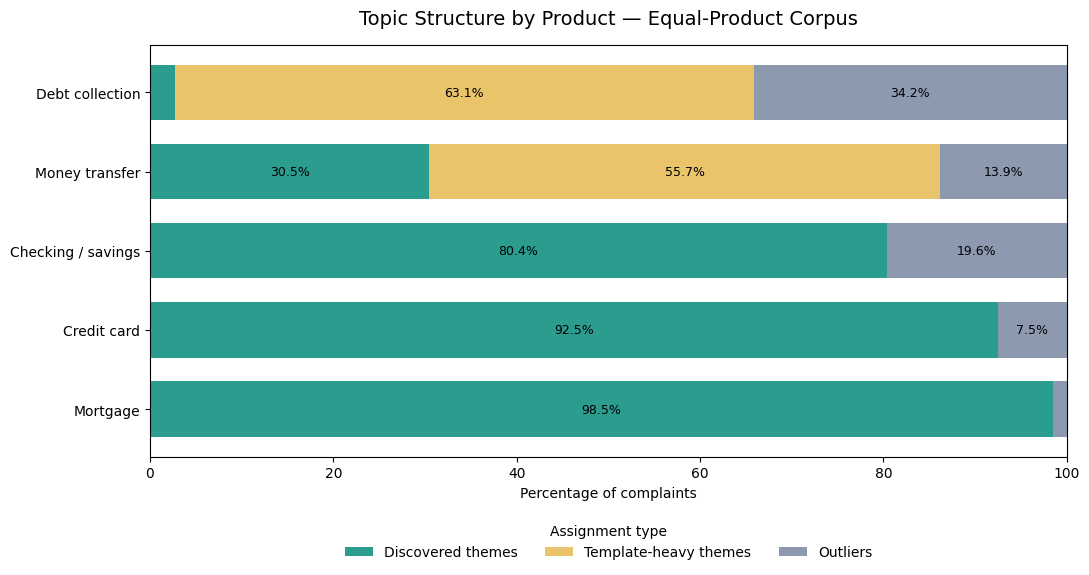

Figure saved to:
/Users/ishika/Documents/AIProject/outputs/notebook7_analysis/figures/equal_product_topic_structure.png


In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

NOTEBOOK7_ANALYSIS_DIR = (
    PROJECT_DIR /
    "outputs" /
    "notebook7_analysis"
)

FIGURE_DIR = NOTEBOOK7_ANALYSIS_DIR / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

product_name_map = {
    "Checking or savings account":
        "Checking / savings",
    "Credit card":
        "Credit card",
    "Debt collection":
        "Debt collection",
    "Money transfer, virtual currency, or money service":
        "Money transfer",
    "Mortgage":
        "Mortgage"
}

plot_data = (
    fair_product_comparison
    .copy()
    .sort_values(
        "discovered_theme_percentage",
        ascending=False
    )
)

plot_data["product_display"] = (
    plot_data["product"].map(product_name_map)
)

plot_data = plot_data.set_index("product_display")

plot_columns = [
    "discovered_theme_percentage",
    "template_heavy_percentage",
    "outlier_percentage"
]

plot_labels = [
    "Discovered themes",
    "Template-heavy themes",
    "Outliers"
]

plot_colors = [
    "#2A9D8F",
    "#E9C46A",
    "#8D99AE"
]

ax = plot_data[plot_columns].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=plot_colors,
    width=0.7
)

ax.set_title(
    "Topic Structure by Product — Equal-Product Corpus",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Percentage of complaints")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.legend(
    plot_labels,
    title="Assignment type",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=3,
    frameon=False
)

# Add percentage labels to sufficiently large segments
for container in ax.containers:
    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() >= 5
        else ""
        for bar in container
    ]
    
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9
    )

plt.tight_layout()

TOPIC_STRUCTURE_FIGURE = (
    FIGURE_DIR /
    "equal_product_topic_structure.png"
)

plt.savefig(
    TOPIC_STRUCTURE_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(TOPIC_STRUCTURE_FIGURE)

## 34. High-Volume Negative Complaint Themes

The following chart ranks clean discovered themes by the number of complaints classified as negative by FinBERT.

Negative volume combines operational scale with sentiment direction. The accompanying percentage shows how concentrated negative sentiment is within each topic. Template-heavy and outlier categories are excluded from this ranking.

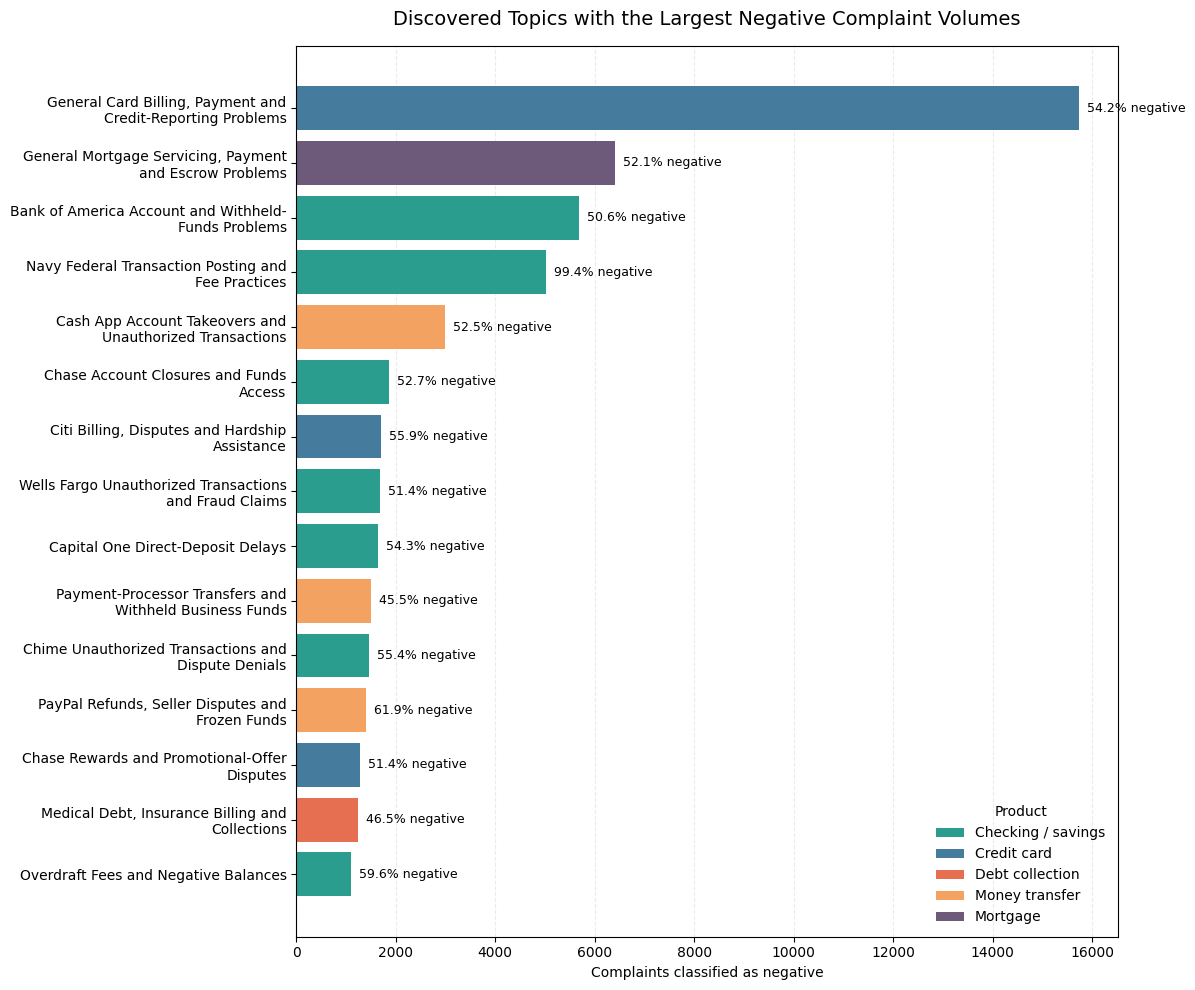

Figure saved to:
/Users/ishika/Documents/AIProject/outputs/notebook7_analysis/figures/highest_negative_topic_volumes.png


In [26]:
import textwrap
from matplotlib.patches import Patch

risk_plot_data = (
    highest_negative_volumes
    .sort_values(
        "negative_complaints",
        ascending=True
    )
    .copy()
)

risk_plot_data["wrapped_topic"] = (
    risk_plot_data["topic_label"]
    .apply(
        lambda value: textwrap.fill(
            value,
            width=38
        )
    )
)

product_colors = {
    "Checking or savings account": "#2A9D8F",
    "Credit card": "#457B9D",
    "Debt collection": "#E76F51",
    "Money transfer, virtual currency, or money service":
        "#F4A261",
    "Mortgage": "#6D597A"
}

bar_colors = (
    risk_plot_data["product"]
    .map(product_colors)
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

bars = ax.barh(
    risk_plot_data["wrapped_topic"],
    risk_plot_data["negative_complaints"],
    color=bar_colors
)

ax.set_title(
    "Discovered Topics with the Largest Negative Complaint Volumes",
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    "Complaints classified as negative"
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for bar, negative_percentage in zip(
    bars,
    risk_plot_data["negative_percentage"]
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {negative_percentage:.1f}% negative",
        va="center",
        fontsize=9
    )

legend_handles = [
    Patch(
        facecolor=color,
        label=product_name_map.get(
            product,
            product
        )
    )
    for product, color in product_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Product",
    loc="lower right",
    frameon=False
)

plt.tight_layout()

NEGATIVE_TOPIC_FIGURE = (
    FIGURE_DIR /
    "highest_negative_topic_volumes.png"
)

plt.savefig(
    NEGATIVE_TOPIC_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(NEGATIVE_TOPIC_FIGURE)

## 35. Export Topic-Modelling Outputs

The final complaint-level dataset combines original complaint metadata, product-specific topic assignments and FinBERT sentiment predictions.

Supporting summary tables are also exported for downstream financial-intelligence KPIs, SQL analysis and dashboard development. The embedding and BERTopic models do not need to be rerun for these later stages.

In [27]:
NOTEBOOK7_ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FULL_TOPIC_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "full_narratives_with_topics_and_sentiment.csv.gz"
)

TOPIC_VOLUME_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "topic_volume_summary.csv"
)

TOPIC_SENTIMENT_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "topic_sentiment_summary.csv"
)

REPETITION_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "topic_repetition_sensitivity.csv"
)

ISSUE_ALIGNMENT_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "topic_issue_alignment.csv"
)

FAIR_COMPARISON_OUTPUT_PATH = (
    NOTEBOOK7_ANALYSIS_DIR /
    "equal_product_topic_comparison.csv"
)

full_topics_sentiment.to_csv(
    FULL_TOPIC_OUTPUT_PATH,
    index=False,
    compression="gzip"
)

topic_volume_summary.to_csv(
    TOPIC_VOLUME_OUTPUT_PATH,
    index=False
)

topic_sentiment_summary.to_csv(
    TOPIC_SENTIMENT_OUTPUT_PATH,
    index=False
)

topic_repetition_summary.to_csv(
    REPETITION_OUTPUT_PATH,
    index=False
)

topic_issue_alignment.to_csv(
    ISSUE_ALIGNMENT_OUTPUT_PATH,
    index=False
)

fair_product_comparison.to_csv(
    FAIR_COMPARISON_OUTPUT_PATH,
    index=False
)

exported_files = [
    FULL_TOPIC_OUTPUT_PATH,
    TOPIC_VOLUME_OUTPUT_PATH,
    TOPIC_SENTIMENT_OUTPUT_PATH,
    REPETITION_OUTPUT_PATH,
    ISSUE_ALIGNMENT_OUTPUT_PATH,
    FAIR_COMPARISON_OUTPUT_PATH,
    TOPIC_STRUCTURE_FIGURE,
    NEGATIVE_TOPIC_FIGURE
]

export_summary = pd.DataFrame({
    "file": [
        path.name
        for path in exported_files
    ],
    "exists": [
        path.exists()
        for path in exported_files
    ],
    "size_mb": [
        round(
            path.stat().st_size / (1024 ** 2),
            2
        )
        if path.exists()
        else np.nan
        for path in exported_files
    ]
})

display(export_summary)

print(
    "Final output directory:",
    NOTEBOOK7_ANALYSIS_DIR
)

,file,exists,size_mb
0,full_narratives_with_topics_and_sentiment.csv.gz,True,149.58
1,topic_volume_summary.csv,True,0.01
2,topic_sentiment_summary.csv,True,0.01
3,topic_repetition_sensitivity.csv,True,0.01
4,topic_issue_alignment.csv,True,0.01
5,equal_product_topic_comparison.csv,True,0.00
6,equal_product_topic_structure.png,True,0.15
7,highest_negative_topic_volumes.png,True,0.48


Final output directory: /Users/ishika/Documents/AIProject/outputs/notebook7_analysis


## 36. Conclusion

This notebook used unsupervised topic modelling to discover recurring complaint themes within 2025 CFPB consumer narratives.

### Methodology Summary

- Prepared 272,429 topic-eligible complaints.
- Removed duplicate training text, producing 210,678 unique narratives.
- Generated 384-dimensional semantic embeddings using `all-MiniLM-L6-v2`.
- Accounted for long narratives using overlapping token chunks and weighted-average embeddings.
- Compared Detailed, Balanced and Broad BERTopic configurations on an equal-product sample.
- Found that global models largely reconstructed existing product categories.
- Applied product-specific topic modelling to discover more useful within-product themes.
- Mapped the resulting topics back to the full complaint dataset.
- Corrected 19,576 complaint assignments where identical text appeared under different products.
- Combined topic assignments with existing FinBERT sentiment predictions.

### Main Findings

- The final models produced 52 technical topics across five products, plus five product-specific outlier categories.
- Related technical clusters were consolidated into 49 interpretable business labels.
- Checking and savings complaints produced the most granular topic structure.
- Credit-card and mortgage complaints were dominated by broad umbrella themes.
- Debt collection contained substantial template-heavy debt-validation language.
- Money-transfer complaints contained prominent Cash App and Zelle campaign-style narratives.
- Template-heavy complaints were retained and explicitly marked rather than silently treated as independent themes.
- Several discovered topics crossed many existing CFPB issue categories, demonstrating that narrative topic modelling adds company-, platform- and behaviour-specific detail beyond the official taxonomy.
- High-volume negative themes included general credit-card problems, mortgage servicing, withheld funds, unauthorized transactions and account-access problems.
- Repetition sensitivity analysis distinguished actual submitted complaint volume from patterns driven by repeated narratives.

### Interpretation Limitations

Topic modelling is unsupervised. Topic boundaries, keywords and business labels are analytical interpretations rather than human-validated ground truth.

Outlier assignments do not indicate incorrect complaints; they indicate narratives that did not fit sufficiently well into a stable cluster.

Template-heavy themes represent real submitted complaint volume, but their counts should not be interpreted as the same number of independently written narratives.

FinBERT sentiment results remain exploratory because no human-labelled complaint reference data were used. Model confidence and aggregate patterns do not prove prediction accuracy.

### Downstream Use

The final complaint-level output combines:

- complaint metadata;
- topic labels and assignment strength;
- template and outlier indicators;
- FinBERT sentiment labels and probabilities.

This dataset provides the analytical foundation for Notebook 8, where complaint volume, topic concentration, negative sentiment, company responses, timeliness and relief outcomes will be combined into financial-intelligence KPIs.